In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

Подготовка данных и определение корреляций

In [13]:
df = pd.read_csv("AmesHousing.csv")
df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())
df["Mas Vnr Area"] = df["Mas Vnr Area"].fillna(df["Mas Vnr Area"].median())
df["BsmtFin SF 1"] = df["BsmtFin SF 1"].fillna(df["BsmtFin SF 1"].median())
df["BsmtFin SF 2"] = df["BsmtFin SF 2"].fillna(df["BsmtFin SF 2"].median())
df["Bsmt Unf SF"] = df["Bsmt Unf SF"].fillna(df["Bsmt Unf SF"].median())
df["Total Bsmt SF"] = df["Total Bsmt SF"].fillna(df["Total Bsmt SF"].median())
df["Bsmt Full Bath"] = df["Bsmt Full Bath"].fillna(df["Bsmt Full Bath"].median())
df["Bsmt Half Bath"] = df["Bsmt Half Bath"].fillna(df["Bsmt Half Bath"].median())
df["Garage Yr Blt"] = df["Garage Yr Blt"].fillna(df["Garage Yr Blt"].median())
df["Garage Cars"] = df["Garage Cars"].fillna(df["Garage Cars"].median())
df["Garage Area"] = df["Garage Area"].fillna(df["Garage Area"].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop(["SalePrice", "Order", "PID", 'MS SubClass', 'Lot Area', 'Lot Frontage'], axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
Overall Qual,1.00,-0.09,0.60,0.57,0.42,0.28,-0.04,0.27,0.55,0.48,...,-0.05,0.34,-0.05,-0.01,-0.19,-0.05,-0.04,-0.02,-0.13,0.33
Overall Cond,-0.09,1.00,-0.37,0.05,-0.13,-0.05,0.04,-0.14,-0.17,-0.16,...,-0.01,-0.15,-0.02,0.01,0.16,-0.05,-0.03,-0.03,0.17,-0.14
Year Built,0.60,-0.37,1.00,0.61,0.31,0.28,-0.03,0.13,0.41,0.31,...,-0.04,0.34,-0.01,-0.01,-0.20,-0.08,-0.03,-0.04,-0.14,0.34
Year Remod/Add,0.57,0.05,0.61,1.00,0.19,0.15,-0.06,0.16,0.30,0.24,...,-0.05,0.33,-0.03,0.01,-0.16,-0.08,-0.03,-0.05,-0.10,0.32
Mas Vnr Area,0.42,-0.13,0.31,0.19,1.00,0.30,-0.01,0.09,0.39,0.39,...,-0.02,0.15,-0.02,0.02,-0.09,-0.02,-0.02,-0.02,-0.07,0.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sale Condition_AdjLand,-0.05,-0.05,-0.08,-0.08,-0.02,-0.03,-0.02,-0.01,-0.04,-0.03,...,-0.00,-0.02,-0.00,-0.00,0.03,1.00,-0.01,-0.01,-0.14,-0.02
Sale Condition_Alloca,-0.04,-0.03,-0.03,-0.03,-0.02,0.03,-0.03,-0.06,-0.04,0.04,...,-0.00,-0.03,-0.00,-0.00,0.04,-0.01,1.00,-0.01,-0.20,-0.03
Sale Condition_Family,-0.02,-0.03,-0.04,-0.05,-0.02,-0.03,-0.00,0.02,-0.00,-0.00,...,0.05,-0.04,0.05,-0.00,-0.01,-0.01,-0.01,1.00,-0.27,-0.04
Sale Condition_Normal,-0.13,0.17,-0.14,-0.10,-0.07,-0.02,0.07,-0.15,-0.14,-0.14,...,0.01,-0.64,-0.09,0.01,0.62,-0.14,-0.20,-0.27,1.00,-0.65


Сначала определяем, в каких столбцах есть NaN, и заполняем их медианными значениями. Потом проводим стандартные процедуры: перевод текста в логические данные, удаление ненужных столбцов, масштабирование, разделение на обучающие данные и проверочные. Потом строится матрица корреляций, показывающая наличие возможной связи между признаками. 

Определение весов данных

In [14]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.215138e+09, tolerance: 1.132e+09
  model = cd_fast.enet_coordinate_descent_gram(
d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.550863e+11, tolerance: 1.132e+09
  model = cd_fast.enet_coordinate_descent_gram(
d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.291091e+11

alpha l2= 100.0
alpha l1 = 1000.0
alpha l1/l2 = 10.0
Оптимальное соотношение L1/L2 (l1_ratio): 0.99
Веса OLS
[ 9.29100e+03  6.71900e+03  9.72000e+03  1.53700e+03  2.63200e+03
  1.35241e+05  5.04070e+04  1.22035e+05 -1.14023e+05  6.91000e+03
  1.29030e+04 -7.29000e+02  1.61320e+04  1.04200e+03 -7.77000e+02
  1.86500e+03  8.99000e+02 -1.98100e+03 -2.55600e+03 -6.40000e+02
  5.08000e+03  4.66000e+02  3.93600e+03  2.39400e+03  1.31400e+03
 -1.91000e+02  1.30000e+02  4.55000e+02  2.83700e+03  7.79300e+03
 -1.16140e+04 -4.85000e+02 -9.93000e+02 -4.50500e+03 -6.31900e+03
  2.22000e+02 -2.92400e+03 -1.34500e+04 -1.38830e+04  8.65000e+02
 -5.50000e+01  1.21100e+03  7.75000e+02  2.91000e+02  2.75600e+03
  1.34000e+02  1.94600e+03 -3.98000e+02 -7.59000e+02  1.73000e+03
 -1.00000e+02 -1.03000e+02 -5.30000e+01  7.74000e+02 -1.27000e+02
  7.80000e+01  1.09100e+03 -2.75000e+02 -6.24000e+02 -1.78900e+03
  1.43900e+03 -3.22800e+03 -2.12000e+03  2.96000e+02  3.31200e+03
 -1.16900e+03 -6.00000e+01 -5.860

d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.222921e+11, tolerance: 1.132e+09
  model = cd_fast.enet_coordinate_descent_gram(
d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.432449e+11, tolerance: 1.082e+09
  model = cd_fast.enet_coordinate_descent_gram(
d:\AI09.10.2026\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.438151e+11

Здесь мы определили веса данных по разным методикам. Вес показывает, насколько сильно меняется целевая переменная (стоимость дома) при изменении данного признака.

Визуализация

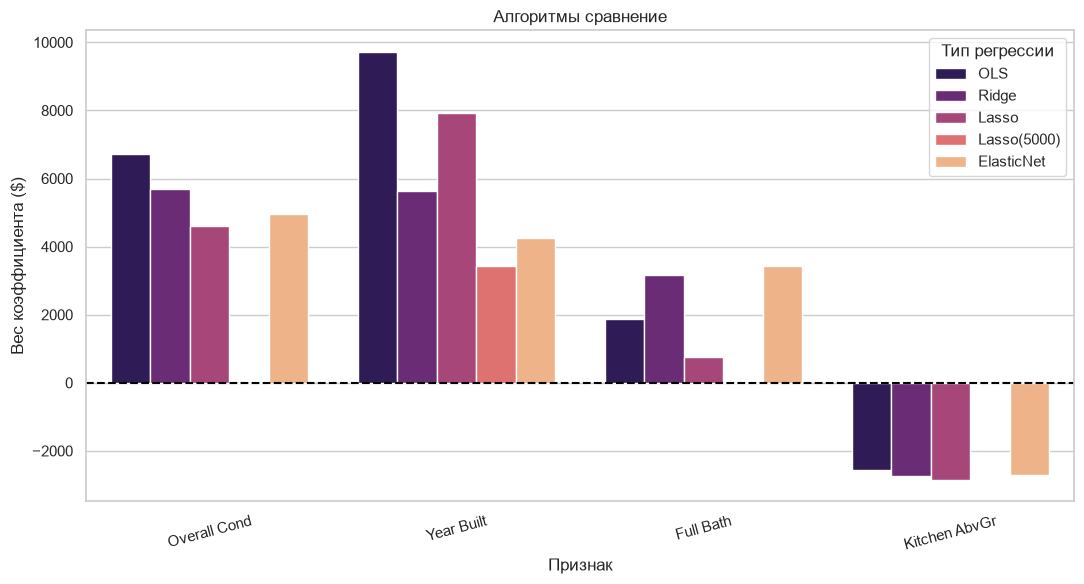

In [18]:
selected_features = ["Year Built", "Overall Cond", "Full Bath", "Kitchen AbvGr"]

weights_df = pd.DataFrame(
    {
        "Признак" : X.columns,
        "OLS" : lr.coef_,
        "Ridge" : ridge_cv.coef_,
        "Lasso" : lasso_cv.coef_,
        "Lasso(5000)" : lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_df = weights_df[weights_df["Признак"].isin(selected_features)]
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)" 
)
plt.figure(figsize=(11,6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()


Видно, что наиболее весомые признаки - год постройки дома и общее состояние. Год постройки также является единственным из выбранных признаков, который имеет вес для Lasso (5000). Видно, что признак "Количество надземных кухонь" обладает отрицательным весом.